# Manutenção Preditiva Industrial — Treinamento do Modelo (AI4I 2020)

**Fatec Pompeia Shunji Nishimura** — Aplicação de Ciência de Dados (Prof. Dr. João Ricardo Favan)

**Integrantes:**
- Hadryan Fortinis de Oliveira Lima
- Raul Victor Matsunaga de Carvalho
- Washingtom Ferreira Gonçalves

Neste notebook fazemos todas as etapas do trabalho:

1. Carregar e conhecer os dados
2. Pré-processamento
3. Engenharia de atributos (4 novos atributos)
4. Redução de dimensionalidade (Rank × PCA)
5. Treinar e comparar modelos
6. Otimizar o melhor modelo (GridSearchCV) e comparar com o modelo padrão
7. Exportar o modelo para a API (`app.py`)

**Dataset:** [AI4I 2020 Predictive Maintenance Dataset](https://www.kaggle.com/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020) — 10.000 leituras de sensores de uma máquina. O objetivo é prever a coluna `Machine failure` (1 = a máquina falhou).

## 1. Importação das bibliotecas

In [1]:
# Se faltar alguma biblioteca: %pip install pandas scikit-learn matplotlib joblib
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42  # semente fixa para os resultados serem reproduzíveis
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2. Carregando os dados

In [2]:
df = pd.read_csv("data/ai4i2020.csv")
print("Linhas e colunas:", df.shape)
df.head()

Linhas e colunas: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
df.describe().round(2)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.01,1538.78,39.99,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.48,179.28,9.97,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1503.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1612.00,46.80,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


## 3. Análise exploratória

Verificamos valores ausentes, linhas duplicadas e o balanceamento da variável alvo.

In [5]:
print("Valores ausentes:", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print()
print(df["Machine failure"].value_counts())
print(f"Taxa de falha: {df['Machine failure'].mean() * 100:.2f}%")

Valores ausentes: 0
Linhas duplicadas: 0

Machine failure
0    9661
1     339
Name: count, dtype: int64
Taxa de falha: 3.39%


Só **3,39%** das leituras são falhas: a base é **muito desbalanceada**. Por isso a acurácia sozinha engana
(um modelo que sempre responde "normal" teria 96,6% de acurácia). Vamos avaliar principalmente o **F1-score**,
a **precisão** e a **revocação (recall)** da classe falha.

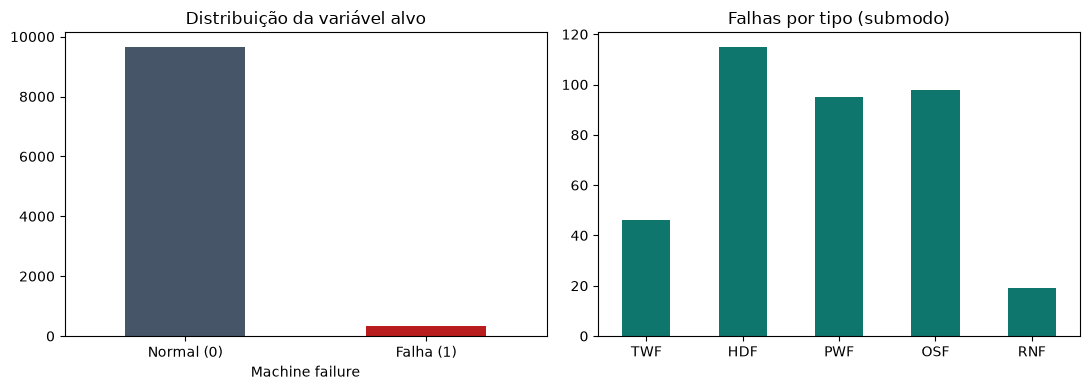

Taxa de falha por tipo de produto (%):
Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64


In [6]:
submodos = ["TWF", "HDF", "PWF", "OSF", "RNF"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

df["Machine failure"].value_counts().plot.bar(ax=ax[0], color=["#475569", "#B91C1C"])
ax[0].set_title("Distribuição da variável alvo")
ax[0].set_xticklabels(["Normal (0)", "Falha (1)"], rotation=0)

df[submodos].sum().plot.bar(ax=ax[1], color="#0F766E")
ax[1].set_title("Falhas por tipo (submodo)")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("Taxa de falha por tipo de produto (%):")
print((df.groupby("Type")["Machine failure"].mean() * 100).round(2))

## 4. Pré-processamento

- `UDI` e `Product ID` são apenas identificadores, não ajudam a prever.
- `TWF`, `HDF`, `PWF`, `OSF` e `RNF` indicam **qual** falha aconteceu: só existem depois da falha, então usá-las seria
  "colar a resposta" (**vazamento de dados / data leakage**). Por isso também são removidas.

In [7]:
df = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"])
df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 5. Engenharia de atributos

Criamos **4 novos atributos** com base na física da máquina:

| Atributo | Fórmula | Ideia |
|---|---|---|
| `Temp_Diff_K` | T. processo − T. ar | pouca diferença = máquina dissipa mal o calor |
| `Mechanical_Power_W` | Torque × rotação × 2π/60 | potência muito baixa ou muito alta causa falha |
| `Wear_Torque_Nm_min` | Desgaste × Torque | ferramenta gasta sob muito esforço = sobrecarga |
| `Torque_Speed_Ratio` | Torque ÷ rotação | muito torque com pouca rotação indica esforço anormal |

A mesma função é usada na API (`app.py`) para calcular esses atributos antes da predição.

In [8]:
def criar_atributos(dados):
    dados = dados.copy()
    dados["Temp_Diff_K"] = dados["Process temperature [K]"] - dados["Air temperature [K]"]
    dados["Mechanical_Power_W"] = dados["Torque [Nm]"] * dados["Rotational speed [rpm]"] * (2 * np.pi / 60)
    dados["Wear_Torque_Nm_min"] = dados["Tool wear [min]"] * dados["Torque [Nm]"]
    dados["Torque_Speed_Ratio"] = dados["Torque [Nm]"] / dados["Rotational speed [rpm]"]
    return dados

df = criar_atributos(df)
novos_atributos = ["Temp_Diff_K", "Mechanical_Power_W", "Wear_Torque_Nm_min", "Torque_Speed_Ratio"]
df[novos_atributos].describe().round(3)

,Temp_Diff_K,Mechanical_Power_W,Wear_Torque_Nm_min,Torque_Speed_Ratio
count,10000.000,10000.000,10000.000,10000.000
mean,10.001,6279.745,4314.665,0.027
std,1.001,1067.418,2826.568,0.009
min,7.600,1148.441,0.000,0.001
25%,9.300,5561.184,1963.650,0.021
50%,9.800,6271.027,4012.950,0.027
75%,11.000,7003.003,6279.000,0.033
max,12.100,10469.923,16497.000,0.064


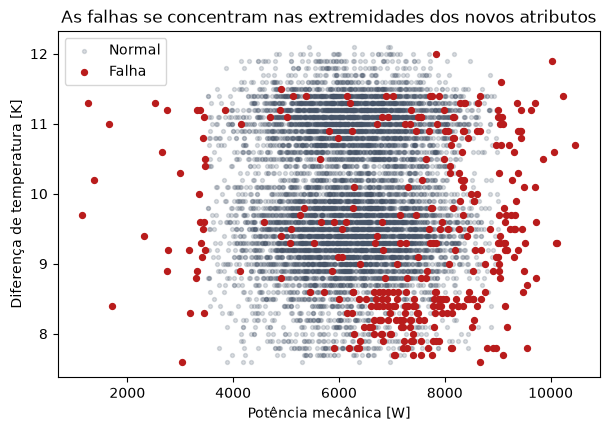

In [9]:
normal = df[df["Machine failure"] == 0]
falha = df[df["Machine failure"] == 1]

plt.figure(figsize=(7, 4.5))
plt.scatter(normal["Mechanical_Power_W"], normal["Temp_Diff_K"], s=8, alpha=0.2, color="#475569", label="Normal")
plt.scatter(falha["Mechanical_Power_W"], falha["Temp_Diff_K"], s=18, color="#B91C1C", label="Falha")
plt.xlabel("Potência mecânica [W]")
plt.ylabel("Diferença de temperatura [K]")
plt.title("As falhas se concentram nas extremidades dos novos atributos")
plt.legend()
plt.show()

## 6. Separação treino / teste

Separamos 80% para treino e 20% para teste, de forma **estratificada** (mantendo a mesma proporção de falhas nos dois).
O teste só é usado no final, para medir o desempenho real.

In [10]:
colunas_originais = ["Type", "Air temperature [K]", "Process temperature [K]",
                     "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
colunas_entrada = colunas_originais + novos_atributos

X = df[colunas_entrada]
y = df["Machine failure"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Falhas no treino:", y_train.sum(), "| Falhas no teste:", y_test.sum())

Treino: (8000, 10) | Teste: (2000, 10)
Falhas no treino: 271 | Falhas no teste: 68


### Transformação das colunas

- Numéricas: preenchimento de ausentes pela mediana + padronização (`StandardScaler`).
- `Type` (L, M, H): codificação *one-hot*.

Tudo fica dentro de um `Pipeline`, assim o ajuste é feito só com os dados de treino (sem vazamento) e o modelo exportado
já contém o pré-processamento.

In [11]:
numericas_originais = colunas_originais[1:]
numericas_com_fe = numericas_originais + novos_atributos

def criar_preprocessador(numericas):
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numericas),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), ["Type"]),
    ])

def criar_pipeline(modelo, numericas=numericas_com_fe, reducao=None):
    etapas = [("preprocessor", criar_preprocessador(numericas))]
    if reducao is not None:
        etapas.append(("reducer", reducao))
    etapas.append(("clf", modelo))
    return Pipeline(etapas)

# Validação cruzada estratificada com 5 partes (folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_cv = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
               "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

def avaliar_cv(pipeline):
    r = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=metricas_cv, n_jobs=-1)
    return {m: round(r[f"test_{m}"].mean(), 4) for m in metricas_cv} | {"f1_std": round(r["test_f1"].std(), 4)}

def avaliar_teste(pipeline):
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]
    return {"accuracy": round(accuracy_score(y_test, pred), 4),
            "precision": round(precision_score(y_test, pred, zero_division=0), 4),
            "recall": round(recall_score(y_test, pred, zero_division=0), 4),
            "f1": round(f1_score(y_test, pred, zero_division=0), 4),
            "roc_auc": round(roc_auc_score(y_test, prob), 4),
            "pr_auc": round(average_precision_score(y_test, prob), 4)}

## 7. Redução de dimensionalidade: Rank × PCA

Depois do pré-processamento temos **12 atributos** (9 numéricos + 3 colunas do one-hot de `Type`).
Comparamos duas técnicas:

- **Rank**: dá uma nota para cada atributo (ANOVA F e Informação Mútua) e mantém os **10 melhores** (`SelectKBest`).
- **PCA**: cria novos componentes que explicam 95% da variância.

In [12]:
prep = criar_preprocessador(numericas_com_fe)
X_train_proc = prep.fit_transform(X_train)
nomes = [n.split("__")[1] for n in prep.get_feature_names_out()]

anova_f, _ = f_classif(X_train_proc, y_train)
info_mutua = mutual_info_classif(X_train_proc, y_train, random_state=SEED)

rank = pd.DataFrame({"atributo": nomes, "anova_f": anova_f.round(1), "info_mutua": info_mutua.round(4)})
rank["novo_atributo"] = rank["atributo"].isin(novos_atributos)
rank = rank.sort_values("anova_f", ascending=False).reset_index(drop=True)
rank.index += 1
rank["selecionado_k10"] = rank.index <= 10
rank

,atributo,anova_f,info_mutua,novo_atributo,selecionado_k10
1,Torque_Speed_Ratio,349.7,0.0471,True,True
2,Torque [Nm],299.7,0.0453,False,True
3,Wear_Torque_Nm_min,285.8,0.0334,True,True
4,Mechanical_Power_W,255.7,0.0466,True,True
5,Temp_Diff_K,100.3,0.0094,True,True
6,Tool wear [min],79.5,0.0106,False,True
7,Air temperature [K],59.6,0.0074,False,True
8,Type_L,17.8,0.0000,False,True
9,Process temperature [K],13.4,0.0039,False,True
10,Rotational speed [rpm],12.8,0.0361,False,True


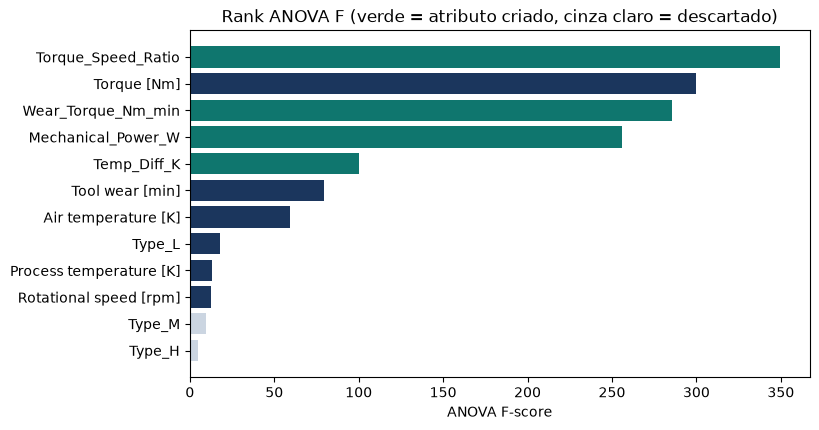

In [13]:
cores = ["#0F766E" if novo else "#1B365D" for novo in rank["novo_atributo"]]
cores = [c if sel else "#CBD5E1" for c, sel in zip(cores, rank["selecionado_k10"])]
plt.figure(figsize=(8, 4.5))
plt.barh(rank["atributo"][::-1], rank["anova_f"][::-1], color=cores[::-1])
plt.title("Rank ANOVA F (verde = atributo criado, cinza claro = descartado)")
plt.xlabel("ANOVA F-score")
plt.show()

O `Torque_Speed_Ratio` (criado por nós) ficou em **1º lugar** e os 4 novos atributos estão entre os 5 melhores. Os descartados foram `Type_M` e `Type_H`.

Componentes necessários para 95% da variância: 5


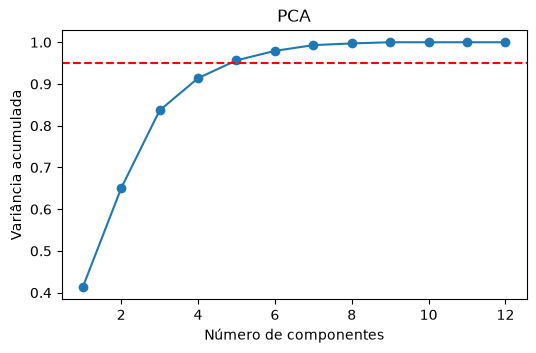

In [14]:
pca = PCA(random_state=SEED).fit(X_train_proc)
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)
n_componentes = int(np.argmax(variancia_acumulada >= 0.95) + 1)
print("Componentes necessários para 95% da variância:", n_componentes)

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.xlabel("Número de componentes")
plt.ylabel("Variância acumulada")
plt.title("PCA")
plt.show()

### Estudo de ablação

Treinamos 3 modelos de árvore em 5 cenários para ver o efeito da engenharia de atributos e da redução de dimensionalidade
(F1-score médio na validação cruzada).

In [15]:
def info_mutua_fixa(X, y):
    return mutual_info_classif(X, y, random_state=SEED)

cenarios = {
    "1. Dados brutos (sem novos atributos)": dict(numericas=numericas_originais, reducao=None),
    "2. Com novos atributos (12)":          dict(numericas=numericas_com_fe, reducao=None),
    "3. Novos atributos + Rank ANOVA k=10": dict(numericas=numericas_com_fe, reducao=SelectKBest(f_classif, k=10)),
    "4. Novos atributos + Rank MI k=10":    dict(numericas=numericas_com_fe, reducao=SelectKBest(info_mutua_fixa, k=10)),
    "5. Novos atributos + PCA 95%":         dict(numericas=numericas_com_fe, reducao=PCA(n_components=0.95, random_state=SEED)),
}
modelos_arvore = {
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
}

ablacao = []
for nome_cenario, cfg in cenarios.items():
    linha = {"cenário": nome_cenario}
    for nome_modelo, modelo in modelos_arvore.items():
        linha[nome_modelo] = avaliar_cv(criar_pipeline(modelo, **cfg))["f1"]
    ablacao.append(linha)

ablacao = pd.DataFrame(ablacao).set_index("cenário")
ablacao

,Random Forest,Gradient Boosting,HistGradientBoosting
cenário,,,
1. Dados brutos (sem novos atributos),0.5946,0.7090,0.7375
2. Com novos atributos (12),0.8769,0.8902,0.8518
3. Novos atributos + Rank ANOVA k=10,0.8703,0.8874,0.8599
4. Novos atributos + Rank MI k=10,0.8690,0.8787,0.8462
5. Novos atributos + PCA 95%,0.5839,0.5412,0.5735


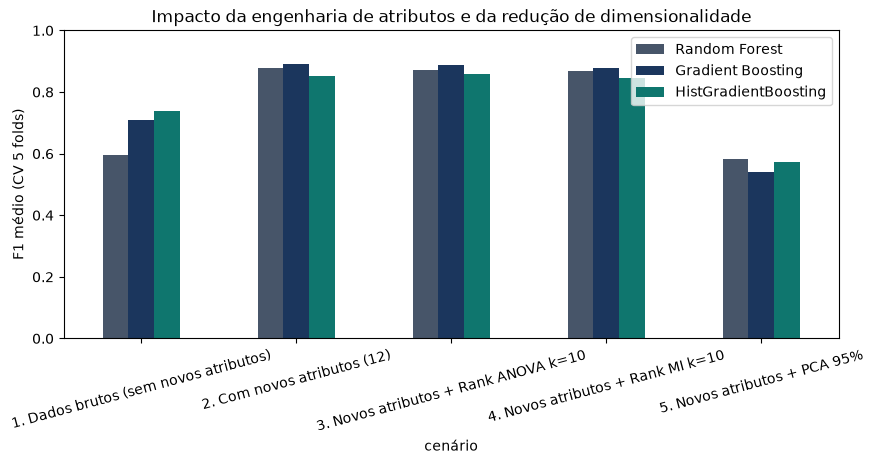

In [16]:
ablacao.plot.bar(figsize=(10, 4), rot=15, color=["#475569", "#1B365D", "#0F766E"])
plt.ylabel("F1 médio (CV 5 folds)")
plt.title("Impacto da engenharia de atributos e da redução de dimensionalidade")
plt.ylim(0, 1)
plt.show()

**Conclusões:**
- Os novos atributos aumentaram muito o F1 (Random Forest: ~0,59 → ~0,88).
- O **Rank ANOVA (k=10)** mantém o desempenho usando menos atributos.
- O **PCA** piorou bastante os modelos de árvore, porque mistura os atributos e perde o significado físico deles.

➡️ **Escolhemos o Rank ANOVA com k = 10** para os próximos passos.

## 8. Treinando e comparando modelos

Treinamos 6 algoritmos com as mesmas condições (novos atributos + Rank ANOVA k=10). O `Dummy` é um modelo "chute",
usado só como referência mínima.

In [17]:
modelos = {
    "Dummy (referência)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=SEED),
    "Rede Neural MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=SEED),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
}

resultados = []
modelos_treinados = {}
for nome, modelo in modelos.items():
    pipe = criar_pipeline(modelo, reducao=SelectKBest(f_classif, k=10))
    cv_res = avaliar_cv(pipe)
    pipe.fit(X_train, y_train)
    teste = avaliar_teste(pipe)
    modelos_treinados[nome] = pipe
    resultados.append({"modelo": nome, "F1 CV": cv_res["f1"], "F1 CV (desvio)": cv_res["f1_std"],
                       "F1 teste": teste["f1"], "Precisão teste": teste["precision"],
                       "Recall teste": teste["recall"], "ROC-AUC teste": teste["roc_auc"],
                       "PR-AUC teste": teste["pr_auc"]})

resultados = pd.DataFrame(resultados).set_index("modelo")
resultados

,F1 CV,F1 CV (desvio),F1 teste,Precisão teste,Recall teste,ROC-AUC teste,PR-AUC teste
modelo,,,,,,,
Dummy (referência),0.0395,0.0070,0.0286,0.0278,0.0294,0.4966,0.0338
Regressão Logística,0.3528,0.0996,0.2697,0.5714,0.1765,0.9279,0.4511
Rede Neural MLP,0.5305,0.0843,0.6168,0.8462,0.4853,0.9662,0.7021
Random Forest,0.8703,0.0295,0.8800,0.9649,0.8088,0.9753,0.8885
Gradient Boosting,0.8874,0.0227,0.8943,1.0000,0.8088,0.9716,0.9041
HistGradientBoosting,0.8599,0.0149,0.8819,0.9492,0.8235,0.9843,0.9012


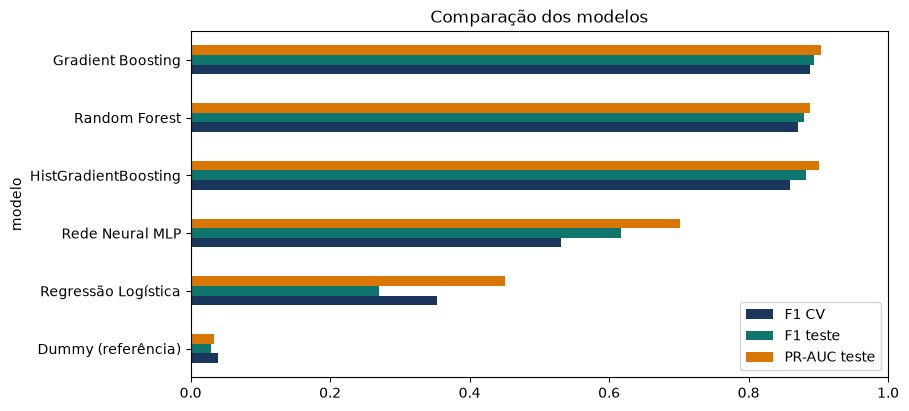

In [18]:
resultados[["F1 CV", "F1 teste", "PR-AUC teste"]].sort_values("F1 CV").plot.barh(
    figsize=(9, 4.5), color=["#1B365D", "#0F766E", "#D97706"])
plt.title("Comparação dos modelos")
plt.xlim(0, 1)
plt.show()

### Escolha do modelo

Os três modelos de árvore (Random Forest, Gradient Boosting e HistGradientBoosting) ficaram bem acima dos demais.
Escolhemos o **HistGradientBoostingClassifier** porque:
- tem F1 alto e com **baixa variação** entre os folds da validação cruzada;
- aceita `class_weight="balanced"`, que ajuda com o desbalanceamento das classes;
- é rápido para treinar e para responder na API.

## 9. Otimização do modelo escolhido (GridSearchCV)

Testamos **216 combinações** de hiperparâmetros com validação cruzada (5 folds), buscando o maior F1.

In [19]:
pipe_busca = criar_pipeline(HistGradientBoostingClassifier(random_state=SEED), reducao=SelectKBest(f_classif, k=10))

grade = {
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_iter": [100, 200, 350],
    "clf__max_leaf_nodes": [15, 31],
    "clf__min_samples_leaf": [10, 20, 35],
    "clf__l2_regularization": [0.0, 0.1, 1.0],
    "clf__class_weight": [None, "balanced"],
}

busca = GridSearchCV(pipe_busca, grade, scoring="f1", cv=cv, n_jobs=-1)
busca.fit(X_train, y_train)

print("Combinações testadas:", len(busca.cv_results_["params"]))
print("Melhores hiperparâmetros:", busca.best_params_)
print(f"Melhor F1 na validação cruzada: {busca.best_score_:.4f}")

Combinações testadas: 216
Melhores hiperparâmetros: {'clf__class_weight': 'balanced', 'clf__l2_regularization': 0.0, 'clf__learning_rate': 0.1, 'clf__max_iter': 350, 'clf__max_leaf_nodes': 31, 'clf__min_samples_leaf': 10}
Melhor F1 na validação cruzada: 0.8901


### Comparação: modelo padrão × modelo otimizado

In [20]:
modelo_padrao = modelos_treinados["HistGradientBoosting"]
modelo_otimizado = busca.best_estimator_

comparacao = pd.DataFrame({
    "Padrão (CV)": avaliar_cv(criar_pipeline(HistGradientBoostingClassifier(random_state=SEED),
                                             reducao=SelectKBest(f_classif, k=10))),
    "Otimizado (CV)": avaliar_cv(modelo_otimizado),
    "Padrão (teste)": avaliar_teste(modelo_padrao),
    "Otimizado (teste)": avaliar_teste(modelo_otimizado),
})
comparacao

,Padrão (CV),Otimizado (CV),Padrão (teste),Otimizado (teste)
accuracy,0.9912,0.9931,0.9925,0.9940
precision,0.9393,0.9716,0.9492,0.9828
recall,0.7933,0.8227,0.8235,0.8382
f1,0.8599,0.8901,0.8819,0.9048
roc_auc,0.9761,0.9714,0.9843,0.9716
pr_auc,0.8787,0.8896,0.9012,0.8866
f1_std,0.0149,0.0074,NaN,NaN


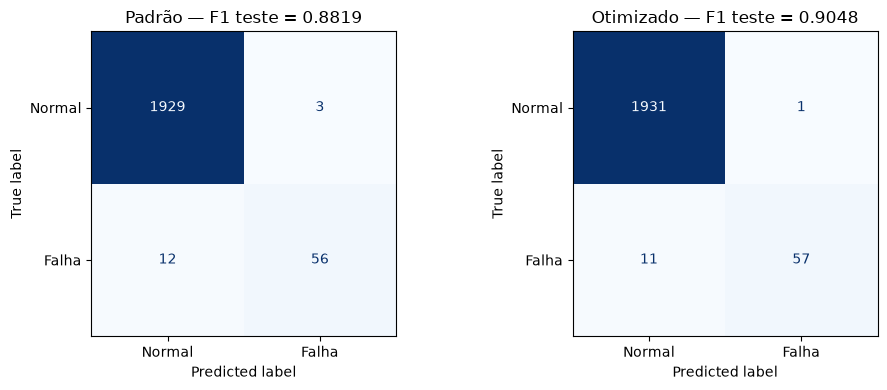

              precision    recall  f1-score   support

      Normal     0.9943    0.9995    0.9969      1932
       Falha     0.9828    0.8382    0.9048        68

    accuracy                         0.9940      2000
   macro avg     0.9885    0.9189    0.9508      2000
weighted avg     0.9939    0.9940    0.9938      2000



In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for eixo, (nome, modelo) in zip(ax, [("Padrão", modelo_padrao), ("Otimizado", modelo_otimizado)]):
    ConfusionMatrixDisplay.from_estimator(modelo, X_test, y_test, display_labels=["Normal", "Falha"],
                                          cmap="Blues", colorbar=False, ax=eixo)
    eixo.set_title(f"{nome} — F1 teste = {f1_score(y_test, modelo.predict(X_test)):.4f}")
plt.tight_layout()
plt.show()

print(classification_report(y_test, modelo_otimizado.predict(X_test), target_names=["Normal", "Falha"], digits=4))

O modelo otimizado aumentou o F1 tanto na validação cruzada quanto no teste e quase zerou os **falsos alarmes**
(falsos positivos), mantendo a detecção das falhas reais. Ele é o modelo exportado para produção.

## 10. Exportando o modelo para produção

Salvamos o pipeline completo (pré-processamento + Rank + modelo) com `joblib`. A API em `app.py` carrega esse
arquivo, calcula os 4 novos atributos com a mesma fórmula deste notebook e devolve a previsão.

In [22]:
import os
os.makedirs("models", exist_ok=True)
joblib.dump(modelo_otimizado, "models/modelo_manutencao_otimizado.joblib", compress=3)

selecionados = list(rank.loc[rank["selecionado_k10"], "atributo"])
metadados = {
    "best_model_name": "HistGradientBoostingClassifier (Otimizado)",
    "dataset": "AI4I 2020 Predictive Maintenance Dataset (n=10.000)",
    "scikit_learn_version": sklearn.__version__,
    "decision_threshold": 0.5,
    "input_columns": colunas_entrada,
    "engineered_features": novos_atributos,
    "selected_features": selecionados,
    "best_hyperparameters": {k.replace("clf__", ""): v for k, v in busca.best_params_.items()},
    "metrics": {"default_test": comparacao["Padrão (teste)"].dropna().to_dict(),
                "tuned_test": comparacao["Otimizado (teste)"].dropna().to_dict()},
}
with open("models/model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadados, f, indent=2, ensure_ascii=False)

print("Modelo e metadados salvos em models/")

Modelo e metadados salvos em models/


### Teste rápido: carregando o modelo salvo e prevendo uma máquina nova

In [23]:
modelo_carregado = joblib.load("models/modelo_manutencao_otimizado.joblib")

maquina = pd.DataFrame([{
    "Type": "L", "Air temperature [K]": 300.8, "Process temperature [K]": 309.4,
    "Rotational speed [rpm]": 1342, "Torque [Nm]": 62.4, "Tool wear [min]": 113,
}])
maquina = criar_atributos(maquina)[colunas_entrada]

prob = modelo_carregado.predict_proba(maquina)[0, 1]
print(f"Probabilidade de falha: {prob:.2%}")
print("Previsão:", "FALHA" if prob >= 0.5 else "NORMAL")

Probabilidade de falha: 100.00%
Previsão: FALHA


## Conclusão

- Os **4 atributos físicos** criados foram os mais importantes do Rank e aumentaram muito o desempenho.
- O **Rank ANOVA (k=10)** foi melhor que o **PCA** para esta base.
- Entre 6 algoritmos, o **HistGradientBoosting** foi escolhido e, após o **GridSearchCV**, ficou ainda melhor que a versão padrão.
- O modelo foi exportado e está disponível na API (`app.py`), que roda dentro do Docker:

```bash
docker build -t manutencao-preditiva .
docker run -p 8000:8000 manutencao-preditiva
```
Depois é só abrir http://localhost:8000

---

**Trabalho desenvolvido por:**

- Hadryan Fortinis de Oliveira Lima
- Raul Victor Matsunaga de Carvalho
- Washingtom Ferreira Gonçalves

*Fatec Pompeia "Shunji Nishimura" · Tecnologia em Ciência de Dados · Aplicação de Ciência de Dados — Prof. Dr. João Ricardo Favan · 2026*